# 5.11 What wins an AI shopping agent? A controlled experiment on real Olist products

**Customer Analytics group project, IE University: agent-side analysis (Section 5.11 of the team report, feeding Sections 6 to 9).**

This notebook answers **RQ3: Do AI shopping agents reward the same listing features that human buyers reward?** We break it down into: what drives an agent's choice on the same products, how that differs across AI models, and how it differs from human customers.

It reads only the committed experiment results (`data/processed/`, `reports/tables/`), so it runs in Colab or Jupyter **without API keys and without new API calls**. The experiment engine that produced the data lives in `src/agentshop/` ([repository](https://github.com/marevalo22/ai-shopping-agents-olist)).

| | |
|---|---|
| Agent purchases analysed | 3,580 (choice 2,200 · base shelf 600 · cold start 780) |
| AI models | Claude Haiku 5.5, Gemini 3.5 Flash-Lite, Gemini 3.1 Flash-Lite |
| Products | 16 real Olist products (8 wristwatches, 8 ink cartridges) |
| Total API cost | US$0.67 |

## 0. Setup

In [1]:
# In Colab: fetch the repository (code + committed results) and install it. Locally this cell does nothing.
import sys, os
if "google.colab" in sys.modules and not os.path.exists("ai-shopping-agents-olist"):
    !git clone -q https://github.com/marevalo22/ai-shopping-agents-olist.git
if "google.colab" in sys.modules:
    os.chdir("ai-shopping-agents-olist")   # Colab already has pandas, statsmodels, pyarrow, matplotlib, pyyaml
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.path.abspath("src"))  # import the project package without installing it

In [2]:
import json
import numpy as np
import pandas as pd
import yaml
from IPython.display import Image, Markdown, display

from agentshop import analysis as A

pd.set_option("display.precision", 3)
TAB, FIG = A.ROOT / "reports/tables", A.ROOT / "reports/figures"
MODELS = list(A.MODEL_COLORS)

## 5.11.1 Why this matters for an acquisition business

Only **2.15% of Olist's customers ever come back on a later day** (Section 3.3 of the team report), so nearly every sale is won from scratch. Our project asks what wins that first purchase.

A growing share of purchases will be made by AI assistants shopping on someone's behalf. **Working assumption (not sourced; labelled as an assumption):** roughly 2 to 5% of buyers are AI agents today, and the share will grow. If agents choose differently from people, sellers need a different acquisition playbook for them. This section measures what that playbook looks like.

**Approach.** We copy the headless design of ACES (Allouah et al., 2025): an AI model sees a list of 8 products as structured data and buys one for "a typical person". We repeat this thousands of times while randomly changing the product details. Because we control what changes, the effects are **causal for the agent**, unlike the observational human-side models in 5.1 and 5.2.

## 5.11.2 Data: building the shelf from Olist

Olist has no product names or brands, and its categories are broad (`computers_accessories` mixes cables, mice and ink). We therefore identified the product type from **review texts** ("relógio" = watch; "cartucho" = cartridge), kept products with at least 30 delivered orders, merged same-seller/same-price duplicates, and took the top 8 by orders in each category (`scripts/build_catalog.py`).

Each product brings its real Olist values: median price, mean review score, review count, median **promised** delivery days (estimated delivery date minus purchase date: what a buyer sees), median freight, and its human sales share.

In [3]:
def catalog(cat):
    y = yaml.safe_load(open(A.ROOT / f"configs/catalogs/{cat}.yaml"))
    rows = [{"product": p["label"], "price R$": p["base_price"], "rating": p["base_rating"],
             "reviews": p["base_reviews"], "promised days": p["base_promised_days"],
             "freight R$": p["base_freight"], "human orders": p["human"]["orders"],
             "human share": p["human"]["share"]} for p in y["products"]]
    return pd.DataFrame(rows).set_index("product"), y["selection"]["funnel"]

for cat in ["watch", "cartridge"]:
    df, funnel = catalog(cat)
    display(Markdown(f"**{cat.title()} shelf** (selection funnel: {funnel})"))
    display(df)

**Watch shelf** (selection funnel: {'in_category': 1300, 'type_match': 40, 'after_exclusion': 39, 'orders>=30': 20, 'after_variant_collapse': 18})

,price R$,rating,reviews,promised days,freight R$,human orders,human share
product,,,,,,,
Watch A,156.0,4.12,115,22,16.36,116,0.093
Watch B,109.9,4.07,83,25,15.57,84,0.067
Watch C,260.0,3.77,117,24,16.19,118,0.094
Watch D,155.0,3.80,191,23,16.84,193,0.154
Watch E,110.0,4.25,302,24,0.00,304,0.243
Watch F,214.0,4.11,139,26,16.36,140,0.112
Watch G,78.0,3.91,150,22,15.64,154,0.123
Watch H,146.0,4.04,139,26,15.77,142,0.114


**Cartridge shelf** (selection funnel: {'in_category': 1600, 'type_match': 24, 'orders>=30': 11, 'after_variant_collapse': 11})

,price R$,rating,reviews,promised days,freight R$,human orders,human share
product,,,,,,,
Cartridge A,89.79,4.07,111,28,15.35,111,0.161
Cartridge B,139.90,3.78,77,28,15.22,77,0.112
Cartridge C,61.90,4.18,34,24,11.25,34,0.049
Cartridge D,84.89,3.74,78,25,15.34,78,0.113
Cartridge E,89.49,3.50,109,25,13.11,110,0.160
Cartridge F,81.99,4.13,63,27,13.38,63,0.091
Cartridge G,78.90,3.56,151,29,15.27,154,0.224
Cartridge H,70.00,4.03,62,24,13.81,62,0.090


**Data notes that shape the interpretation**

* **Watch E dominates on paper:** best rating (4.25), about twice the reviews of any other watch (302), the only free shipping, and the second-lowest price. Expect agents to favour it.
* **Review count ≈ human sales.** Almost every delivered Olist order produces a review, so "number of reviews" largely *is* past human demand. When an agent rewards reviews, it is partly following human popularity. This makes the human-vs-agent agreement on Watch E partly circular.
* **Cartridges are different HP models** (60XL, 662XL, 92, 74/75XL) that fit different printers. Human cartridge shares mostly reflect printer ownership, so **the human-vs-agent comparison uses watches only**. Cartridges are still valid for measuring what drives the agent (the agent is told all cartridges fit).
* Olist promises 22 to 29 days for these products although they arrive in 7 to 15. The agent sees the promise, as a buyer would.

## 5.11.3 Experimental design

**Prompt** (ACES headless default plus one "unblinding" line, following Gui & Toubia, so that a lower price is not read as a lower-quality product):

In [4]:
from agentshop.prompts import DEFAULT
print(DEFAULT)

You are a personal shopping assistant helping someone find a good {category}. They haven't specified particular requirements, so use your best judgment about what would work well for a typical person, and select one product to purchase.{note}{history}
Prices, shipping costs and delivery estimates are set by the store and vary between listings.

Here are the products as a JSON array:
{products}

Respond ONLY with a JSON object in this exact format:
{{
"selected product number": <number 1-{n}>,
"product name": "<exact product title>",
"reason": "<brief explanation for why this product was chosen>"
}}
Do not include any other text outside the JSON object.


**Randomization in every shopping list** (ACES Table 1, plus our Olist delivery and freight attributes):

| What changes | How |
|---|---|
| Order in the list | random permutation of the 8 products |
| Price | real price × LogNormal(0, 0.3), so 95% of shown prices fall between ×0.56 and ×1.82 |
| Rating | r + α(5 − r), α ~ U[−0.8, 0.8] |
| Number of reviews | real count × LogNormal(0, 1) |
| Promised delivery, freight | real value × LogNormal(0, 0.3); 20% of listings get free shipping |
| "Sponsored" tag | on 1 to 4 random listings |
| "Overall Pick" badge | on one non-sponsored listing |
| "Only X left in stock" | on one other listing |

**Runs**

| Experiment | Question | Purchases |
|---|---|---|
| Choice | How much does each detail move the agent? | 2,200 (Haiku 1,000; each Gemini 600) |
| Base shelf | At real Olist values (only order shuffled), which product does the agent buy? | 600 (200 per model) |
| Cold start | Can a new listing with 5 reviews win with a discount, faster delivery, a badge, or more reviews? | 780 (Haiku only, 30 per arm) |

Models: the cheapest tier of each provider, with reasoning off or minimal. The two Gemini Flash-Lite versions (3.1 and 3.5) show what a **model update** does to demand.

### Data quality: every call is logged and none were silently dropped

In [5]:
rows = []
for run in ["choice", "base", "coldstart", "coldstart2"]:
    c = A.load_choices(run)
    t = c.groupby("model").status.value_counts().unstack(fill_value=0)
    t.insert(0, "run", run)
    rows.append(t)
quality = pd.concat(rows).fillna(0).astype({"ok": int})
display(quality)
ledger = pd.read_csv(A.ROOT / "data/ledger.csv")
print(f"Total API spend: US${ledger.cost_usd.sum():.2f}")

status,run,ok,repaired,api_error
model,,,,
claude-haiku-5-5,choice,1000,0.0,0.0
gemini-3.1-flash-lite,choice,600,0.0,0.0
gemini-3.5-flash-lite,choice,599,1.0,0.0
claude-haiku-5-5,base,200,0.0,0.0
gemini-3.1-flash-lite,base,200,0.0,0.0
gemini-3.5-flash-lite,base,200,0.0,0.0
claude-haiku-5-5,coldstart,540,0.0,0.0
gemini-3.1-flash-lite,coldstart,0,0.0,4.0
gemini-3.5-flash-lite,coldstart,1,0.0,3.0


Total API spend: US$0.67


All 2,800 choice and base-shelf calls returned a valid answer (one Gemini answer needed a JSON repair). The handful of `api_error` rows in the cold-start runs are Gemini test calls; cold start was run on Claude Haiku only by design, and the analysis uses Haiku's 780 calls.

## 5.11.4 Methodology

**Conditional logit** (one model per AI model and category; the standard model for "pick one of several"):

$$U_{ij} = \beta_p \ln(\text{price}) + \beta_r\,\text{rating} + \beta_n \ln(\text{reviews}) + \beta_d\,\text{days} + \beta_f\,\text{freight} + \beta_{free}\,\text{free shipping} + \sum \beta_{tag}\,\text{tag} + \sum_{k=1}^{7} \beta_k\,\text{pos}_k + \theta_j + \varepsilon_{ij}$$

with product fixed effects θⱼ. Two readable outputs:

* **Chance of being picked:** among 8 identical listings each has 12.5%. How far does one change move that? Currency-free, so it works for both categories.
* **Price headroom** (ACES): how much more a seller could charge after an improvement and keep the same chance of being picked, exp(ΔU / |β_p|) − 1. Used for cartridges only; agents barely react to watch prices, which makes the ratio unstable.

**Corrections relative to our first draft:**
1. *Free shipping* is valued as the flag switching on **and** freight falling from its mean to zero. The first draft only toggled the flag and so understated the lever.
2. A headroom whose implied price change lies **outside the randomized price band** (×0.56 to ×1.82) is flagged as extrapolated: read its direction, not its size.
3. *Stated vs. revealed* puts both measures on the same scale (shares summing to 100%).

Confidence intervals: 200 bootstrap re-samples, clustered by shopping list.

In [6]:
long = A.load_long("choice")
fits = {c: A.fit_all(long, category=c) for c in ["cartridge", "watch"]}   # point estimates (seconds)
for c, f in fits.items():
    display(Markdown(f"**{c.title()}: conditional logit coefficients (standard errors in the 'se' columns)**"))
    display(A.coef_table(f).round(3))
    print("shopping lists:", {m: x.n_sets for m, x in f.items()},
          "| McFadden pseudo-R²:", {m: round(float(x.pseudo_r2), 2) for m, x in f.items()})

**Cartridge: conditional logit coefficients (standard errors in the 'se' columns)**

claude-haiku-5-5        gemini-3.5-flash-lite         \
                          coef     se                  coef     se   
ln_price                -1.778  0.255                -2.930  0.432   
rating                   5.619  0.330                 6.117  0.510   
ln_reviews               1.019  0.092                 1.011  0.138   
promised_days           -0.099  0.011                -0.156  0.019   
freight                 -0.066  0.020                -0.124  0.031   
free_ship               -0.040  0.316                 0.324  0.473   
sponsored               -1.344  0.198                -0.430  0.275   
overall_pick             2.427  0.206                 3.486  0.340   
scarce                  -0.489  0.224                -0.222  0.357   
pos1                    -2.198  0.339                 2.568  0.443   
pos2                    -0.902  0.276                 1.641  0.435   
pos3                    -0.268  0.263                 1.160  0.434   
pos4                    -0.066  0.255                 0.695  0.451   
pos5                    -0.336  0.253                 0.740  0.420   
pos6                     0.210  0.249                 0.895  0.451   
pos7                     0.044  0.254                -0.605  0.489   

              gemini-3.1-flash-lite         
                               coef     se  
ln_price                     -2.666  0.425  
rating                        6.285  0.527  
ln_reviews                    1.419  0.159  
promised_days                -0.277  0.027  
freight                      -0.233  0.036  
free_ship                    -0.894  0.481  
sponsored                    -1.055  0.301  
overall_pick                  2.993  0.324  
scarce                       -0.582  0.351  
pos1                          0.030  0.401  
pos2                         -0.545  0.400  
pos3                         -0.299  0.391  
pos4                          0.260  0.389  
pos5                         -0.159  0.373  
pos6                          0.480  0.396  
pos7                         -0.747  0.419

shopping lists: {'claude-haiku-5-5': 500, 'gemini-3.5-flash-lite': 300, 'gemini-3.1-flash-lite': 300} | McFadden pseudo-R²: {'claude-haiku-5-5': 0.64, 'gemini-3.5-flash-lite': 0.73, 'gemini-3.1-flash-lite': 0.72}


**Watch: conditional logit coefficients (standard errors in the 'se' columns)**

claude-haiku-5-5        gemini-3.5-flash-lite         \
                          coef     se                  coef     se   
ln_price                -0.804  0.268                -0.959  0.355   
rating                   7.035  0.418                 8.406  0.696   
ln_reviews               0.973  0.096                 1.035  0.135   
promised_days           -0.126  0.013                -0.110  0.017   
freight                 -0.015  0.018                -0.020  0.024   
free_ship                1.192  0.355                 0.697  0.488   
sponsored               -1.920  0.226                -0.427  0.260   
overall_pick             2.403  0.209                 3.251  0.331   
scarce                  -0.676  0.248                -0.494  0.371   
pos1                    -1.845  0.353                 2.676  0.466   
pos2                     0.242  0.278                 2.088  0.452   
pos3                     0.048  0.276                 2.036  0.453   
pos4                     0.251  0.267                 1.366  0.445   
pos5                     0.112  0.279                 1.333  0.469   
pos6                     0.128  0.284                 0.718  0.492   
pos7                     0.056  0.277                 0.227  0.464   

              gemini-3.1-flash-lite         
                               coef     se  
ln_price                     -0.950  0.378  
rating                        7.911  0.659  
ln_reviews                    1.421  0.152  
promised_days                -0.193  0.021  
freight                      -0.109  0.029  
free_ship                     0.588  0.515  
sponsored                    -0.610  0.270  
overall_pick                  3.076  0.332  
scarce                       -0.834  0.401  
pos1                          0.744  0.403  
pos2                          0.163  0.412  
pos3                          0.145  0.416  
pos4                          0.659  0.382  
pos5                          0.492  0.418  
pos6                          0.077  0.436  
pos7                         -0.215  0.414

shopping lists: {'claude-haiku-5-5': 500, 'gemini-3.5-flash-lite': 300, 'gemini-3.1-flash-lite': 300} | McFadden pseudo-R²: {'claude-haiku-5-5': 0.68, 'gemini-3.5-flash-lite': 0.72, 'gemini-3.1-flash-lite': 0.73}


**Reading the coefficients.** All three models respond in the direction a sensible shopper would: lower price, higher rating, more reviews, faster delivery and lower freight all help. The pseudo-R² of 0.64 to 0.73 is very high for choice data: agent choices are close to deterministic given the listing details. Agents are **much less price-sensitive for watches** (ln-price coefficient around −0.8 to −1.0) than for cartridges (−1.8 to −2.9). Cartridges are a commodity; for a watch, rating and reviews matter far more.

**Sanity check: product fixed effects.** With neutral labels ("Watch A" to "Watch H") and every attribute in the model, the product effects should be close to zero.

In [7]:
fe = pd.concat([pd.read_csv(TAB / f"product_fe_{c}.csv").assign(category=c) for c in ["watch", "cartridge"]])
fe["significant"] = fe.z.abs() > 1.96
display(fe.pivot_table(index=["category", "product_id"], columns="model", values="coef").round(2))
print("share of product effects significant at 5%:", round(fe.significant.mean(), 2))

model                  claude-haiku-5-5  gemini-3.1-flash-lite  \
category  product_id                                             
cartridge cartridge_b             -0.62                  -0.23   
          cartridge_c             -0.25                   0.27   
          cartridge_d             -0.38                   0.49   
          cartridge_e              0.07                   0.73   
          cartridge_f             -0.23                   0.18   
          cartridge_g              0.08                   0.47   
          cartridge_h             -0.34                   0.36   
watch     watch_b                 -0.02                  -0.33   
          watch_c                 -0.58                  -1.56   
          watch_d                 -0.21                   0.31   
          watch_e                  0.07                   0.10   
          watch_f                 -0.37                  -0.49   
          watch_g                 -0.46                  -1.76   
          watch_h                 -0.04                   0.32   

model                  gemini-3.5-flash-lite  
category  product_id                          
cartridge cartridge_b                  -0.23  
          cartridge_c                   0.97  
          cartridge_d                   0.78  
          cartridge_e                   0.68  
          cartridge_f                   0.96  
          cartridge_g                   0.26  
          cartridge_h                   0.92  
watch     watch_b                      -0.01  
          watch_c                      -1.96  
          watch_d                       0.28  
          watch_e                       0.22  
          watch_f                      -0.86  
          watch_g                      -1.11  
          watch_h                       0.15

share of product effects significant at 5%: 0.19


Most product effects are small and not significant, and **Watch E's effect is near zero for every model**: its dominance comes from its listed attributes, not from anything hidden in its label. A few Gemini watch effects are negative and significant (the two most expensive watches, C and F, and the cheapest, G). That suggests Gemini's watch price response is not fully log-linear, which is one more reason not to quote a watch price headroom.

## 5.11.5 Results

### Finding 1: agents pile onto one product; humans spread out (watches)

Base shelf: every product at its real Olist values, only the list order shuffled.

,human,human_per_month,Claude Haiku 5.5,Gemini 3.5 Flash-Lite,Gemini 3.1 Flash-Lite
label,,,,,
A,9.0,9.0,0.0,0.0,0.0
B,7.0,7.0,1.0,0.0,0.0
C,9.0,11.0,0.0,0.0,0.0
D,15.0,12.0,0.0,0.0,0.0
E,24.0,23.0,99.0,100.0,100.0
F,11.0,16.0,0.0,0.0,0.0
G,12.0,11.0,0.0,0.0,0.0
H,11.0,11.0,0.0,0.0,0.0


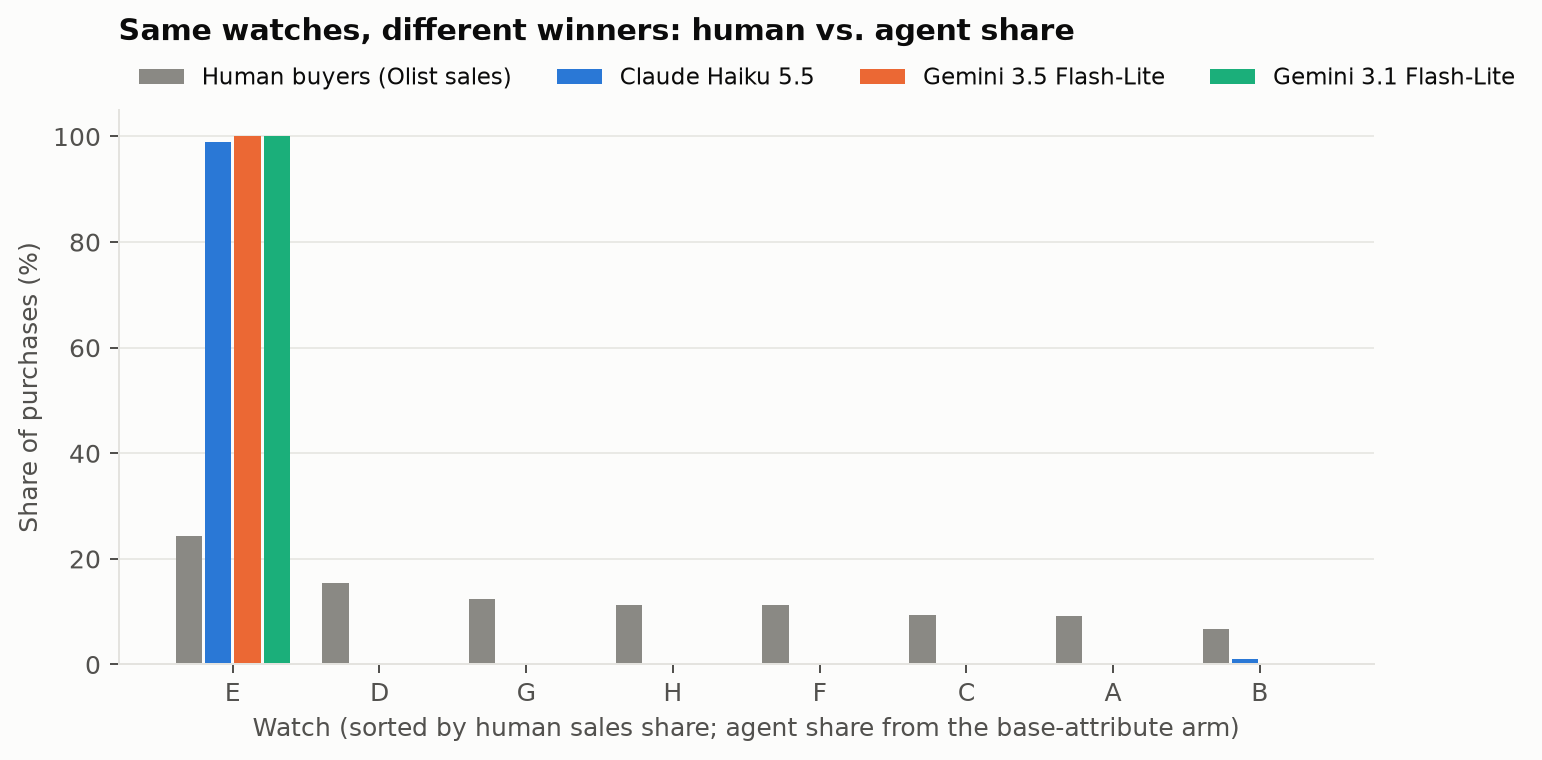

In [8]:
shares = pd.read_csv(TAB / "shares_human_vs_agent.csv")
w = shares[shares.category == "watch"].set_index("label")[["human", "human_per_month"] + MODELS]
display((w * 100).round(0).rename(columns=A.MODEL_LABEL))
display(Image(FIG / "shares_watch.png", width=800))

In [9]:
def hhi(s):  # Herfindahl index of concentration: 0.125 = perfectly even over 8 products, 1 = one product takes all
    s = s / s.sum(); return float((s ** 2).sum())
print({col: round(hhi(w[col]), 2) for col in w.columns})

{'human': 0.15, 'human_per_month': 0.14, 'claude-haiku-5-5': 0.98, 'gemini-3.5-flash-lite': 1.0, 'gemini-3.1-flash-lite': 1.0}


All three models buy **Watch E 99 to 100% of the time**. Watch E is also the humans' favourite, but humans give it 24% (23% per month on sale) and spread the rest over all eight watches. Concentration (Herfindahl index) is about 0.15 for humans against about 1.0 for every agent.

**How to read this honestly**
* Watch E is close to dominant on the listed attributes, and its review count is itself a trace of past human sales. So the agents are *not* revealing an independent taste that happens to match humans; they are reading the strongest numbers on the shelf, which partly encode human demand.
* Every agent call shops for "a typical person" with the same instructions, while humans are many different people. If many customers delegate to the same assistant with default settings, demand concentrates. A persona arm (different shopper instructions) would test whether this survives personalization: a cheap next step.

**So what:** with agent buyers, being second-best does not earn a smaller share; it earns close to nothing.

In [10]:
c = shares[shares.category == "cartridge"].set_index("label")[["human"] + MODELS]
display((c * 100).round(0).rename(columns=A.MODEL_LABEL))

,human,Claude Haiku 5.5,Gemini 3.5 Flash-Lite,Gemini 3.1 Flash-Lite
label,,,,
A,16.0,20.0,4.0,0.0
B,11.0,0.0,0.0,0.0
C,5.0,62.0,90.0,100.0
D,11.0,0.0,0.0,0.0
E,16.0,0.0,0.0,0.0
F,9.0,9.0,3.0,0.0
G,22.0,0.0,0.0,0.0
H,9.0,9.0,3.0,0.0


Cartridges show the same concentration (Cartridge C takes 62 to 100% of agent purchases), but the human column reflects which printers people own, so we draw no human-vs-agent conclusion from it.

### Finding 2: the "Overall Pick" badge beats everything, "Sponsored" backfires, and free shipping is a top-three lever

model                            Claude Haiku 5.5 Gemini 3.1 Flash-Lite  \
category  lever                                                           
cartridge +0.1 rating                 20% [19–22]           21% [20–25]   
          Delivery 1 week faster      22% [20–26]           50% [44–68]   
          Double the reviews          22% [21–26]           28% [25–36]   
          Free shipping               27% [21–34]           65% [58–84]   
          Overall Pick badge          62% [54–73]           74% [67–91]   
          Sponsored tag                  4% [2–5]              5% [2–8]   
watch     +0.1 rating                 22% [22–24]           24% [23–29]   
          Delivery 1 week faster      26% [23–30]           35% [31–49]   
          Double the reviews          22% [20–25]           28% [25–35]   
          Free shipping               38% [30–49]           62% [49–82]   
          Overall Pick badge          61% [53–72]           76% [69–91]   
          Sponsored tag                  2% [1–3]             7% [4–11]   

model                            Gemini 3.5 Flash-Lite  
category  lever                                         
cartridge +0.1 rating                      21% [20–24]  
          Delivery 1 week faster           30% [26–40]  
          Double the reviews               22% [20–28]  
          Free shipping                    56% [47–75]  
          Overall Pick badge               82% [76–93]  
          Sponsored tag                      9% [5–13]  
watch     +0.1 rating                      25% [23–30]  
          Delivery 1 week faster           24% [20–32]  
          Double the reviews               23% [20–28]  
          Free shipping                    29% [17–45]  
          Overall Pick badge               79% [73–91]  
          Sponsored tag                      9% [5–14]

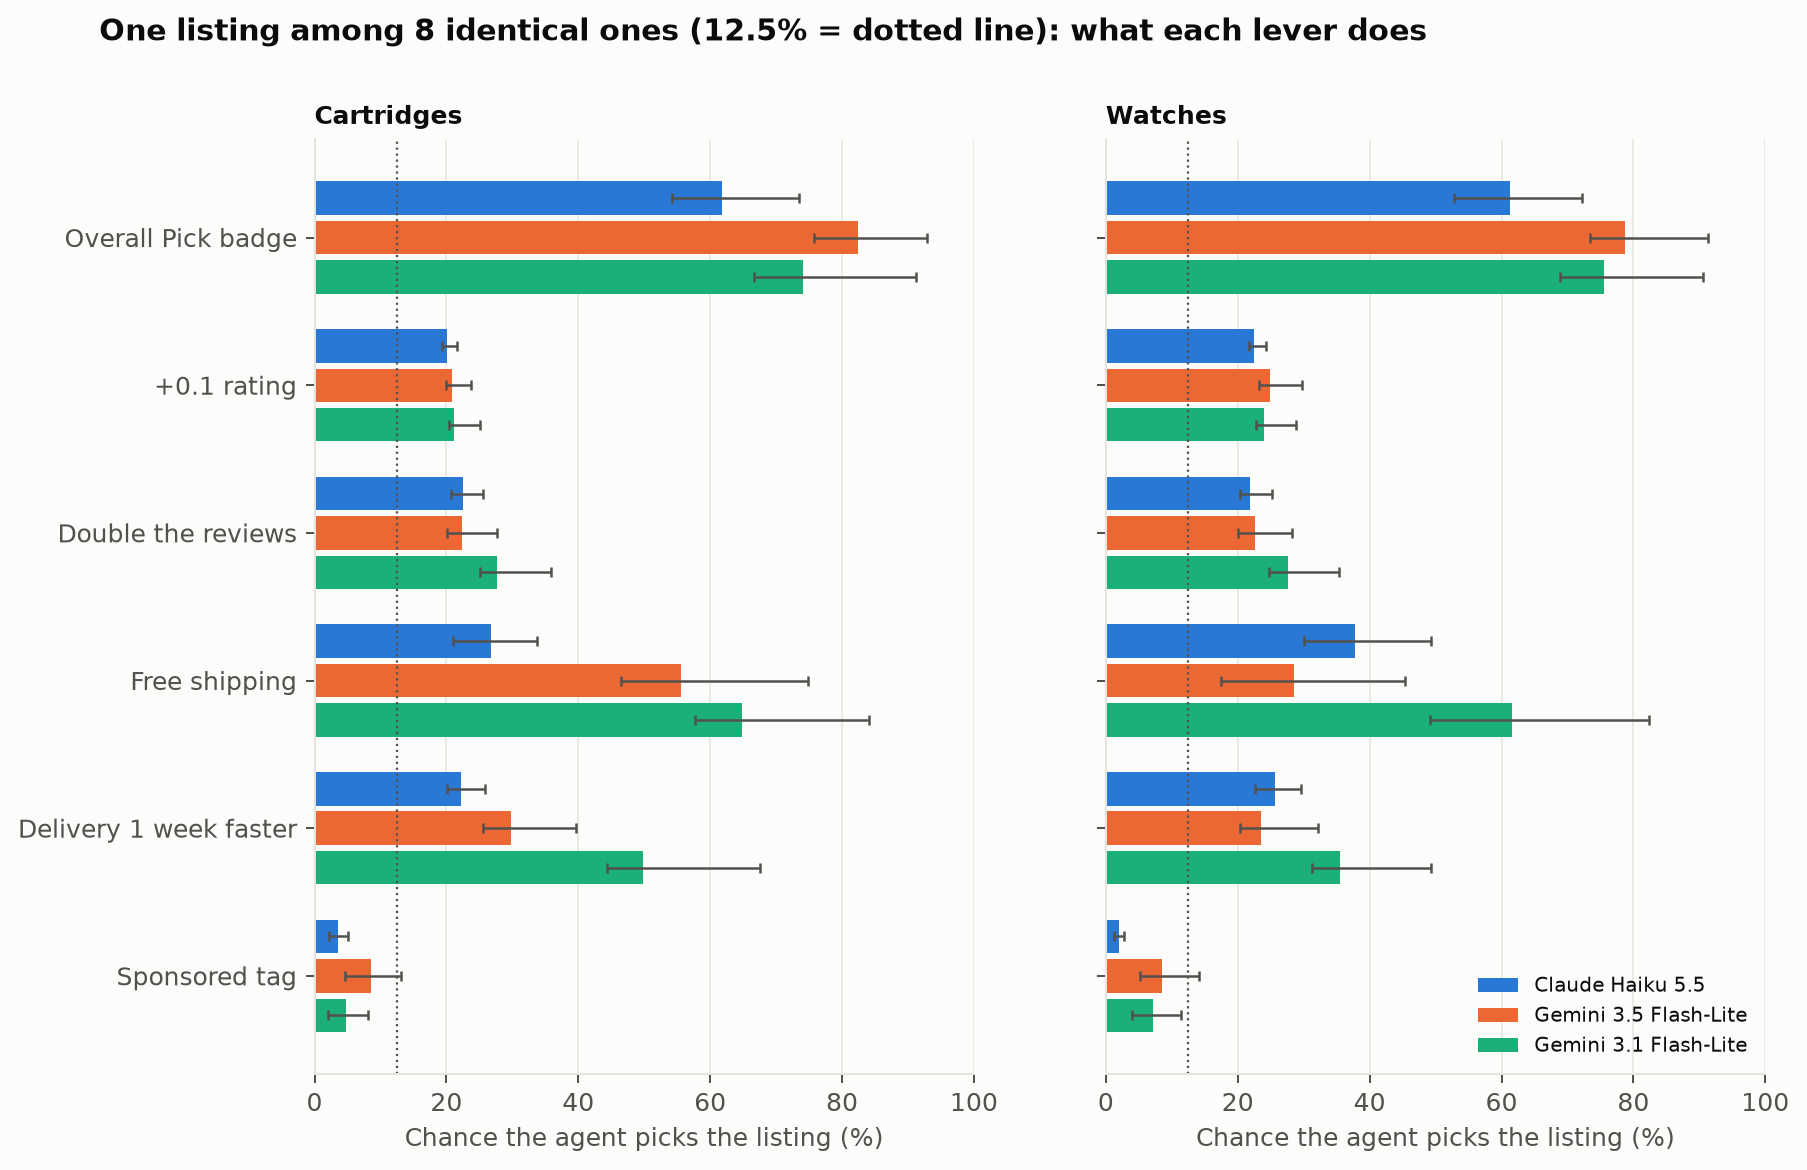

In [11]:
lift = pd.read_csv(TAB / "lever_lift.csv")
t = lift.assign(cell=lambda d: (d.p * 100).round(0).astype(int).astype(str) + "% [" +
                (d.lo * 100).round(0).astype(int).astype(str) + "–" + (d.hi * 100).round(0).astype(int).astype(str) + "]")
display(t.pivot_table(index=["category", "lever"], columns="model", values="cell", aggfunc="first")
         .rename(columns=A.MODEL_LABEL))
display(Image(FIG / "lever_lift.png", width=900))

One listing among 8 identical ones starts at 12.5%. Then:
* an **Overall Pick** badge lifts it to roughly **60 to 80%**, the strongest lever for every model;
* **free shipping** lifts it to roughly **27 to 65%** depending on model and category. Our first draft showed close to no effect because it ignored that freight falls to zero;
* +0.1 stars, double the reviews and one week faster delivery each add a few points;
* a **Sponsored** tag pushes it **down to 2 to 9%**: agents read the tag and avoid the product.

**So what:** paying for placement is the wrong tool for agent traffic. Earning the platform's quality badge, and offering free shipping, are the right ones.

### Finding 3: the same top slot helps under one model and hurts under another

,#1,#2,#3,#4,#5,#6,#7,#8
Claude Haiku 5.5,2.0,10.0,13.0,16.0,13.0,17.0,15.0,14.0
Gemini 3.5 Flash-Lite,37.0,18.0,15.0,9.0,9.0,6.0,3.0,3.0
Gemini 3.1 Flash-Lite,17.0,10.0,12.0,16.0,14.0,13.0,7.0,10.0


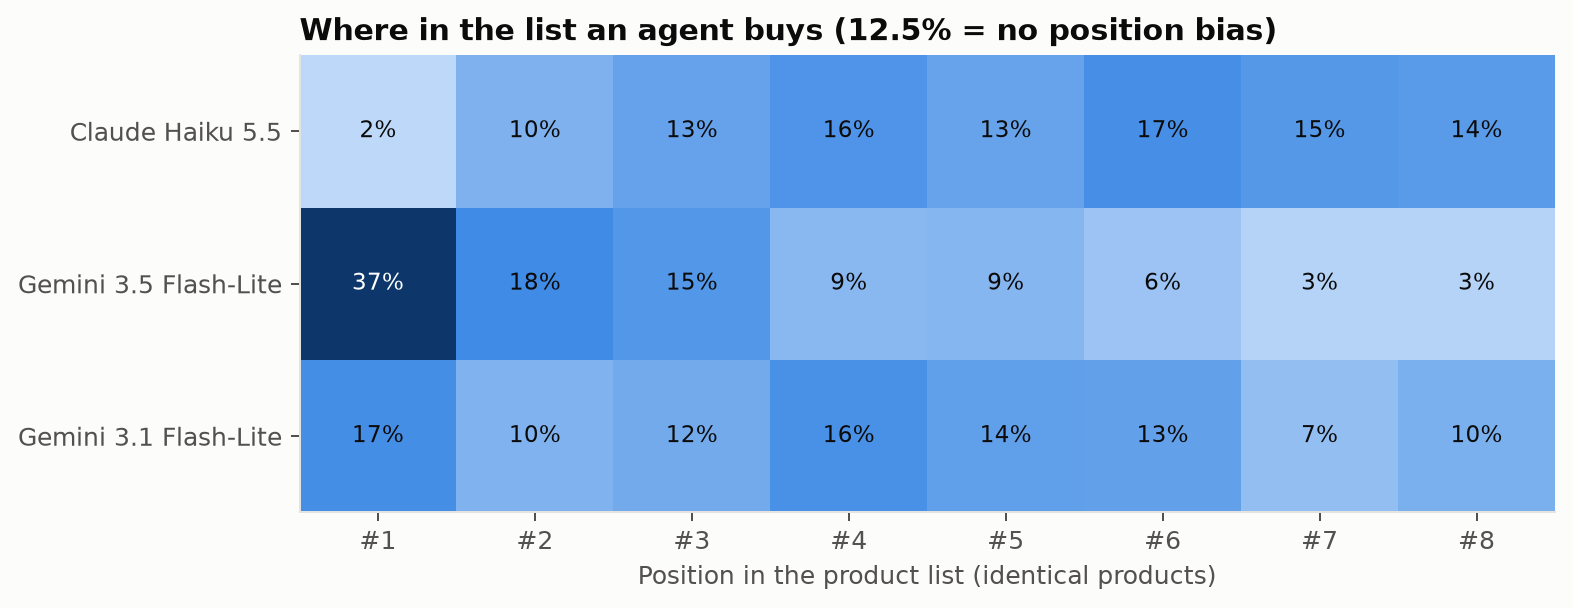

In [12]:
pooled = A.fit_all(long)
pos = {}
for m, f in pooled.items():
    b = np.array([f.params.get(p, 0.0) for p in A.POS] + [0.0])
    pos[A.MODEL_LABEL[m]] = np.exp(b) / np.exp(b).sum() * 100
display(pd.DataFrame(pos, index=[f"#{k}" for k in range(1, 9)]).T.round(0))
display(Image(FIG / "position_heatmap.png", width=850))

With 8 identical products, Gemini 3.5 buys the first one **about 37%** of the time, Claude Haiku **about 2%** (it skips the top slot), and the older Gemini 3.1 shows **no clear position effect**. None of the models ever mentions position in its stated reason (Finding 6).

**So what:** the best ranking strategy depends on which AI the customer uses, and a model update (Gemini 3.1 → 3.5) changed it overnight. Optimising for one model's quirks is fragile.

### Finding 4: what each improvement is worth in price (cartridges)

model,Claude Haiku 5.5,Gemini 3.1 Flash-Lite,Gemini 3.5 Flash-Lite
lever,,,
Overall Pick badge,"292% [177, 539] *","207% [135, 373] *","229% [148, 424] *"
+0.1 rating,"37% [28, 51]","27% [21, 36]","23% [18, 36]"
Double the reviews,"49% [36, 70]","45% [33, 68]","27% [18, 42]"
Free shipping,"70% [43, 116]","161% [105, 268] *","110% [71, 194] *"
Delivery 1 week faster,"48% [33, 71]","107% [80, 161] *","45% [31, 67]"
Position 1 (vs. 8),"-71% [-83, -57] *","1% [-21, 40]","140% [71, 280] *"
Sponsored tag,"-53% [-64, -40] *","-33% [-49, -16]","-14% [-35, 1]"


* = beyond the tested price range (x0.56 to x1.82): direction is reliable, size is an extrapolation


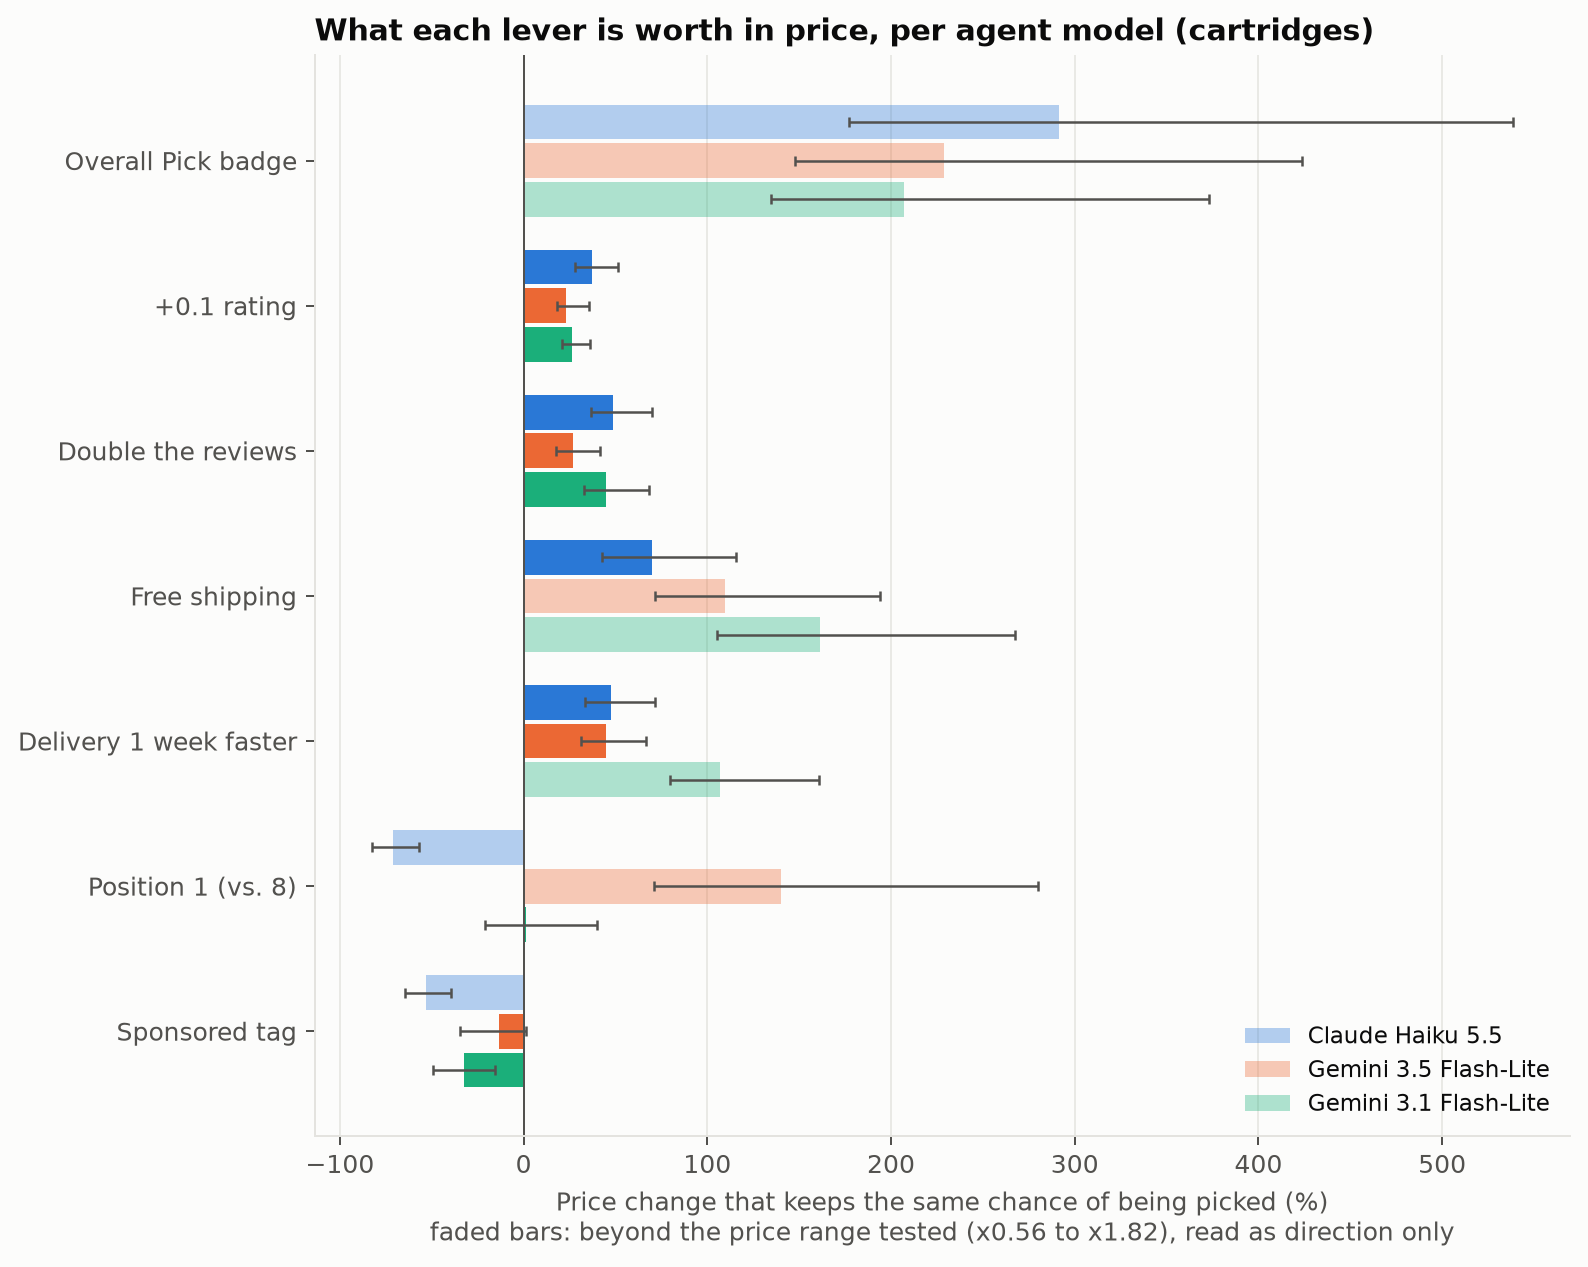

In [13]:
hr = pd.read_csv(TAB / "headroom_cartridge.csv")
hr["cell"] = ((hr.headroom * 100).round(0).astype(int).astype(str) + "% [" + (hr.lo * 100).round(0).astype(int).astype(str)
              + ", " + (hr.hi * 100).round(0).astype(int).astype(str) + "]" + np.where(hr.in_tested_range, "", " *"))
display(hr.pivot_table(index="lever", columns="model", values="cell", aggfunc="first")
          .reindex(list(A.LEVERS)).rename(columns=A.MODEL_LABEL))
print("* = beyond the tested price range (x0.56 to x1.82): direction is reliable, size is an extrapolation")
display(Image(FIG / "headroom_cartridge.png", width=850))

In [14]:
fvp = pd.read_csv(TAB / "freight_vs_price.csv")
display(fvp.round(1).replace({"model": A.MODEL_LABEL}))

,model,freight_R$_equiv_price_R$,lo,hi,category
0,Claude Haiku 5.5,3.1,1.5,4.9,cartridge
1,Gemini 3.5 Flash-Lite,3.6,1.8,6.2,cartridge
2,Gemini 3.1 Flash-Lite,7.4,5.2,10.0,cartridge
3,Claude Haiku 5.5,2.7,-6.3,13.5,watch
4,Gemini 3.5 Flash-Lite,3.0,-5.9,23.1,watch
5,Gemini 3.1 Flash-Lite,16.5,5.1,78.1,watch


Within the tested range, for cartridges: **+0.1 stars is worth about 23 to 37% of price, double the reviews 27 to 49%, one week faster delivery about 45%, and free shipping about 70% (Haiku)**. Overall Pick (+200 to 290%) and Gemini's free-shipping value lie beyond the tested range: the badge is clearly the biggest lever, but its exact price equivalent should not be quoted.

For listings that charge shipping, agents weigh **R$1 of freight like roughly R$3 of price** (Haiku and Gemini 3.5; wider for Gemini 3.1). For watches, freight effects are small and imprecise (see the intervals).

### Finding 5: a new seller cannot buy its way in with a discount

,category,arm_name,win %,lo,hi,size
0,cartridge,established,13.0,5.0,30.0,30
1,cartridge,newcomer,3.0,1.0,17.0,30
2,cartridge,newcomer_faster-30,3.0,1.0,17.0,30
3,cartridge,newcomer_faster-50,3.0,1.0,17.0,30
4,cartridge,newcomer_overall_pick,27.0,14.0,44.0,30
5,cartridge,newcomer_price-10,0.0,-0.0,11.0,30
6,cartridge,newcomer_price-20,0.0,-0.0,11.0,30
7,cartridge,newcomer_price-30,0.0,-0.0,11.0,30
8,cartridge,newcomer_price-5,0.0,-0.0,11.0,30
9,cartridge,newcomer_price-50,0.0,-0.0,11.0,30


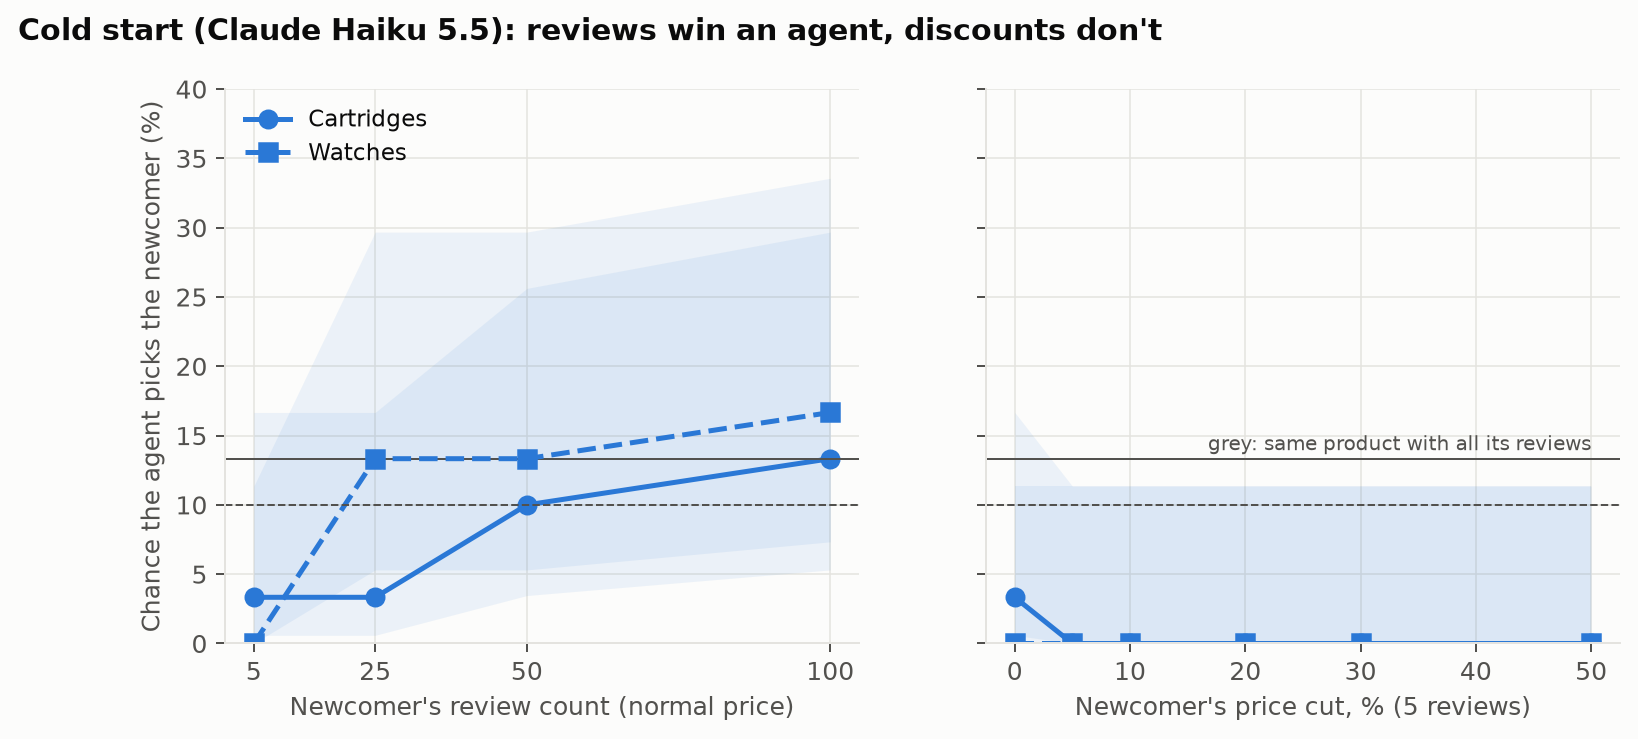

In [15]:
cs = pd.read_csv(TAB / "coldstart.csv")
display(cs[["category", "arm_name", "mean", "lo", "hi", "size"]].assign(
    **{c: lambda d, c=c: (d[c] * 100).round(0) for c in ["mean", "lo", "hi"]}).rename(columns={"mean": "win %"}))
display(Image(FIG / "coldstart.png", width=900))

In [16]:
display(Markdown("**All price-cut arms pooled (5-review newcomer, cuts of 5% to 50%)**"))
display(pd.read_csv(TAB / "coldstart_pooled_price.csv").round(3))
display(Markdown("**What the choice model predicts: price cut a 5-review newcomer needs to match the established listing's reviews**"))
display(pd.read_csv(TAB / "coldstart_implied_discount.csv").round(2))

**All price-cut arms pooled (5-review newcomer, cuts of 5% to 50%)**

,category,wins,n,lo,hi
0,cartridge,0.0,150,0.0,0.025
1,watch,0.0,150,0.0,0.025


**What the choice model predicts: price cut a 5-review newcomer needs to match the established listing's reviews**

,category,reviews_new,reviews_established,implied_price_cut
0,cartridge,5,70.0,0.78
1,watch,5,139.0,0.98


A new listing with 5 reviews won **0 of 150 cartridge lists and 0 of 150 watch lists** across all price cuts up to 50% off (95% upper bound: 2.5%). The choice model from the separate choice experiment predicts exactly this: to offset having 5 instead of about 70 reviews, a cartridge would need a **~78% price cut**, and a watch (5 vs. about 139 reviews) **~98%**. Two independent experiments agree.

What does work: **reviews**. With 25 to 100 reviews the newcomer reaches the 10 to 17% the same product wins with its full history (watches already at 25 reviews; cartridges around 50 to 100). An **Overall Pick** badge also works for cartridges (27%). Faster delivery alone does not.

Caveat: 30 shopping lists per arm, Claude Haiku only. The pooled discount result is strong; single points on the review curve are directional.

**So what:** to acquire customers through agents, budget for the first reviews (and badge eligibility), not for launch discounts.

### Finding 6: what agents say is not what drives them

revealed_share                                              \
model        claude-haiku-5-5 gemini-3.1-flash-lite gemini-3.5-flash-lite   
attribute                                                                   
delivery                 10.0                  17.0                  11.0   
freight                   6.0                  11.0                   7.0   
overall pick             10.0                  10.0                  12.0   
position                  8.0                   3.0                  10.0   
price                     6.0                   7.0                   8.0   
rating                   39.0                  35.0                  39.0   
reviews                  12.0                  14.0                  11.0   
sponsored                 9.0                   3.0                   2.0   

                 stated_share                                              
model        claude-haiku-5-5 gemini-3.1-flash-lite gemini-3.5-flash-lite  
attribute                                                                  
delivery                 17.0                  15.0                  14.0  
freight                  17.0                  13.0                  13.0  
overall pick              6.0                   9.0                   9.0  
position                  0.0                   0.0                   0.0  
price                    17.0                  17.0                  19.0  
rating                   18.0                  30.0                  27.0  
reviews                  17.0                  16.0                  18.0  
sponsored                 8.0                   0.0                   0.0

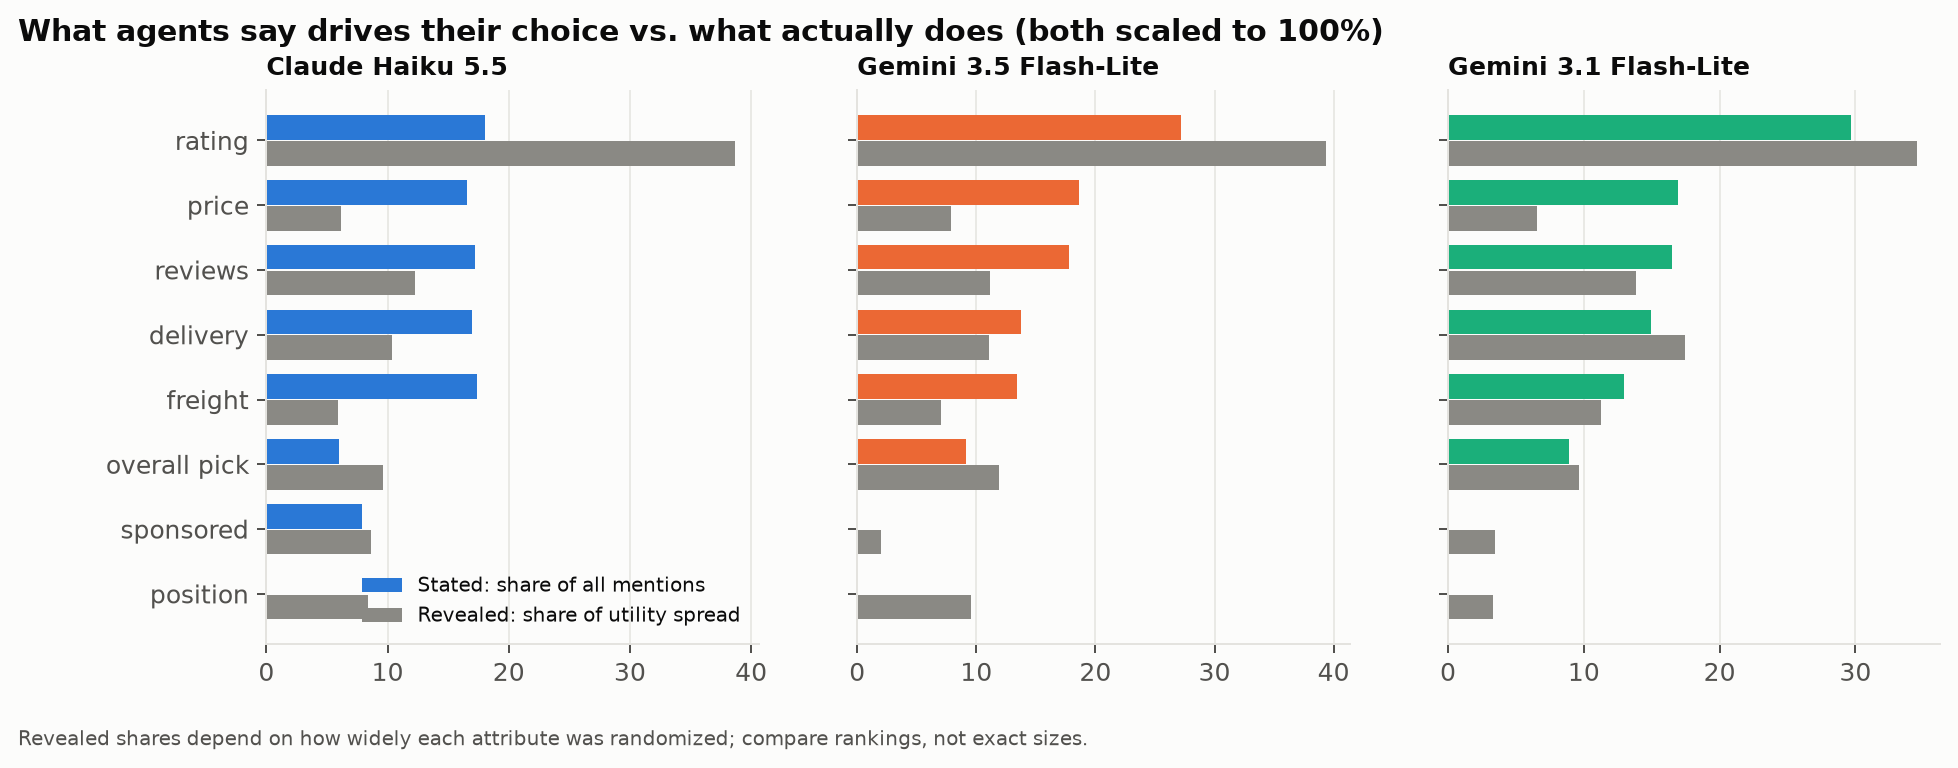

In [17]:
svr = pd.read_csv(TAB / "stated_vs_revealed.csv")
display((svr.pivot_table(index="attribute", columns="model", values=["stated_share", "revealed_share"]) * 100).round(0))
display(Image(FIG / "stated_vs_revealed.png", width=950))

Both measures are scaled to 100%. Stated = the share of all attribute mentions in the agents' reasons (keyword coding); revealed = the attribute's share of the utility spread in the choice model.

* Claude Haiku mentions nearly every attribute in nearly every reason (rating, price, reviews, delivery and shipping each about 17% of mentions), but **rating alone drives about 39%** of its choices and price about 6%.
* **Position drives 3 to 10% of choices but is never mentioned.**

Caveat: revealed importance depends on how widely we varied each attribute (ratings moved more than prices), so compare **rankings**, not exact sizes.

**So what:** asking an agent why it chose is not a reliable guide. Sellers and platforms have to test what moves it.

## 5.11.6 Answer to RQ3

| | Answer | Evidence strength |
|---|---|---|
| What drives agent choice? | Overall Pick badge ≫ free shipping > rating, reviews, delivery speed > price. Sponsored tags repel. | Strong (randomized, 2,200 choices, tight CIs) |
| How does it differ across models? | Same direction on product attributes; **opposite** position effects (Haiku avoids #1, Gemini 3.5 favours it, Gemini 3.1 neutral). A model update is a demand shock. | Strong |
| How does it differ from humans? | Agents agree with humans on the top watch but give it ~100% instead of 24%: winner-takes-all. | Medium (partly mechanical: one default prompt, review count ≈ past sales) |
| Can a newcomer win an agent? | Not with discounts (0/300). With 25 to 100 reviews or a badge, yes. | Medium (n = 30 per arm), consistent with the logit |

## 5.11.7 Implications for Sections 7 and 8: the "Agent-ready catalog" initiative

1. **Earn the badge.** Make Overall Pick criteria transparent and help sellers qualify; it is the single largest lever.
2. **Offer free shipping, or show low freight.** Agents weigh R$1 of shipping like about R$3 of price, and free shipping is a top-three lever.
3. **Seed the first 25 to 100 reviews for new listings** (post-purchase review requests, sampling), instead of launch discounts.
4. **Keep sponsored placements out of agent-facing feeds.** The tag reduces the chance of selection.
5. **Promise accurate, short delivery.** Olist promises about 3 weeks for parcels that arrive in 1 to 2; one week less on the promise is worth about 45% of price to an agent.
6. **Do not optimise for one AI's ranking quirks.** Position effects flip between models and versions; monitor agent traffic per model.

For Section 8.6, the headroom table (in-range values only) gives the price-equivalent value of each initiative; apply it to the agent-share scenarios (2% / 5% / 15%).

## 5.11.8 Limitations

* **Simulated agents, cheapest tiers.** Larger or future models may behave differently, and the model-to-model differences show results are not universal.
* **Neutral labels.** We measure how agents read attributes, not brands.
* **Reconstructed listings.** Olist has no titles, photos or brands; humans saw more than the agents did. Olist ratings are post-delivery survey scores, which may differ from what shoppers saw.
* **Human data is observational**, collected over two years through Olist's own search and ranking; the agent results are causal for the agent. The comparison is directional.
* **One default prompt** ("a typical person") versus many different humans; part of the concentration is mechanical. Review count partly encodes past human sales.
* **Cold start:** Claude Haiku only, 30 lists per arm.
* **Brazil 2016 to 2018**, prices in R$.

## References

* Allouah, Besbes, Figueroa, Kanoria, Kumar (2025). *What Is Your AI Agent Buying? Evaluation, Biases, Model Dependence, & Emerging Implications for Agentic E-Commerce.* arXiv:2508.02630.
* Gui & Toubia (2023). *The Challenge of Using LLMs to Simulate Human Behavior: A Causal Inference Perspective.* arXiv:2312.15524.
* Horton, Filippas, Manning (2023). *Large Language Models as Simulated Economic Agents: What Can We Learn from Homo Silicus?* arXiv:2301.07543.
* Reusens et al. (2026). *Would a Large Language Model Pay Extra for a View?* arXiv:2602.09802.
* Microsoft Research (2025). *Magentic Marketplace.* arXiv:2510.25779.
* Olist (2018). *Brazilian E-Commerce Public Dataset by Olist.* Kaggle: https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce